# Walmart Store Sales Forecasting: rebuilt from the data-preparation step

Notebooks 01 and 02 (data understanding and EDA) told us what the data looks like. This notebook starts from there and builds the whole forecasting pipeline in order:

1. Load and merge the files
2. Check the weekly date grid
3. Split by time (train until a cutoff, forecast the next 39 weeks)
4. Define the metric (WMAE)
5. Baselines: last observed value and seasonal naive
6. Build features as they would look on the day we make the forecast
7. Train a model that corrects the seasonal-naive forecast
8. Compare, and find out where each model wins or loses

**Facts from the EDA that shape the design**
- Sales have a strong yearly pattern, with Thanksgiving and Christmas peaks, so last year's value is a strong predictor.
- `IsHoliday` does not flag the weeks just before Christmas, which are the biggest weeks. We add our own holiday-proximity feature.
- Some Store-Department series are short or have gaps, so every prediction needs a fallback.
- Negative sales exist. We keep them and use an error metric (MAE-based) that is fine with them.

## 0. Setup

In [17]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

# Where the Kaggle files live (relative to this notebook). The env var is only a convenience.
RAW_DIR = Path(os.environ.get("WALMART_RAW_DIR", "../data/raw"))
REPORT_DIR = Path(os.environ.get("WALMART_REPORT_DIR", "../reports"))

# Run the whole notebook once per cutoff: "2011-10-28" (window 1) and "2012-01-27" (window 2)
CUTOFF = pd.Timestamp("2012-01-27")   # last week the model is allowed to see
HORIZON = 39                          # number of weeks we forecast after the cutoff
HOLIDAY_WEIGHT = 5                    # WMAE counts holiday weeks 5 times
TAG = str(CUTOFF.date())              # used in output file names

## 1. Load and merge

`train.csv` has the sales. `stores.csv` adds store Type and Size. We do not use `features.csv` yet
(temperature, fuel price, CPI, unemployment, markdowns). MarkDown1-5 only exist from Nov 2011, so they are
missing for all of our training period, and the other columns are weak predictors compared with last year's sales.
They are an easy extension later.

In [18]:
train = pd.read_csv(RAW_DIR / "train.csv", parse_dates=["Date"])
stores = pd.read_csv(RAW_DIR / "stores.csv")

df = train.merge(stores, on="Store", how="left", validate="many_to_one")
df = df.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)

# Checks: one row per Store-Dept-Date, and every store found its Type/Size
assert not df.duplicated(["Store", "Dept", "Date"]).any()
assert df["Type"].notna().all() and df["Size"].notna().all()

df["Type"] = df["Type"].map({"A": 0, "B": 1, "C": 2})   # numeric code for the model
print(df.shape)
print(df["Date"].min().date(), "to", df["Date"].max().date())
df.head()

(421570, 7)
2010-02-05 to 2012-10-26


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size
0,1,1,2010-02-05,24924.50,False,0,151315
1,1,1,2010-02-12,46039.49,True,0,151315
2,1,1,2010-02-19,41595.55,False,0,151315
3,1,1,2010-02-26,19403.54,False,0,151315
4,1,1,2010-03-05,21827.90,False,0,151315


## 2. Check the weekly date grid

Later we look up "sales 52 weeks ago" by subtracting 364 days. That only works if the data is on a regular weekly grid.

In [19]:
all_dates = pd.DatetimeIndex(np.sort(df["Date"].unique()))
steps = pd.Series(all_dates).diff().dropna().unique()
assert len(steps) == 1 and steps[0] == pd.Timedelta(days=7), steps
print(len(all_dates), "weekly dates, every 7 days")

holiday_by_date = df.groupby("Date")["IsHoliday"].max()
print("Holiday weeks in the data:")
print(holiday_by_date[holiday_by_date].index.strftime("%Y-%m-%d").tolist())

143 weekly dates, every 7 days
Holiday weeks in the data:
['2010-02-12', '2010-09-10', '2010-11-26', '2010-12-31', '2011-02-11', '2011-09-09', '2011-11-25', '2011-12-30', '2012-02-10', '2012-09-07']


## 3. Split by time

- **Training data:** everything up to `CUTOFF` (Oct 28, 2011)
- **Evaluation window:** the next 39 weeks (Nov 4, 2011 to Jul 27, 2012)

39 weeks is the length of the competition's real test period, and the window contains Thanksgiving, Christmas,
Super Bowl and Easter. The old 12-week window (Aug to Oct 2012) had almost no big holidays, so it flattered
every model. Nothing after the cutoff is used for training or for features.

In [20]:
val_dates = all_dates[all_dates > CUTOFF][:HORIZON]
train_df = df[df["Date"] <= CUTOFF]
val_df = df[df["Date"].isin(val_dates)]

print("Training :", train_df["Date"].min().date(), "to", train_df["Date"].max().date(), f"({len(train_df):,} rows)")
print("Evaluate :", val_dates.min().date(), "to", val_dates.max().date(), f"({len(val_df):,} rows, {len(val_dates)} weeks)")
print("Holiday weeks in the evaluation window:", holiday_by_date[val_dates][lambda s: s].index.strftime("%Y-%m-%d").tolist())

Training : 2010-02-05 to 2012-01-27 (305,982 rows)
Evaluate : 2012-02-03 to 2012-10-26 (115,588 rows, 39 weeks)
Holiday weeks in the evaluation window: ['2012-02-10', '2012-09-07']


## 4. The metric: WMAE

The competition uses weighted mean absolute error. Holiday weeks count 5 times, because holiday weeks matter most to the business:

$$WMAE = \frac{\sum_i w_i\,|y_i-\hat y_i|}{\sum_i w_i},\qquad w_i = 5 \text{ (holiday week)},\; 1 \text{ otherwise}$$

We test it on a tiny example we can do by hand before trusting it.

In [21]:
def wmae(y_true, y_pred, is_holiday, holiday_weight=HOLIDAY_WEIGHT):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    if np.isnan(y_pred).any() or np.isnan(y_true).any():
        raise ValueError("NaN in y_true or y_pred")
    w = np.where(np.asarray(is_holiday, bool), holiday_weight, 1.0)
    return float(np.sum(w * np.abs(y_true - y_pred)) / np.sum(w))

def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true, float) - np.asarray(y_pred, float))))

# Hand check: errors are 2 (holiday, weight 5) and 3 (normal, weight 1) -> (5*2 + 1*3) / 6
assert abs(wmae([10, 20], [12, 17], [True, False]) - 13 / 6) < 1e-9
print("WMAE test passed")

WMAE test passed


## 5. Baselines

Before any machine learning we need simple forecasts to beat.

**Baseline 1, last observed:** repeat the series' most recent training value for every future week.

**Baseline 2, seasonal naive:** use the sales from the same week last year (52 weeks earlier).

Some series have no value 52 weeks back (short history, or a gap), so we use a fallback chain:
> last year's value, then the series' last observed value, then the department's median, then the overall median.

The medians come from training data only.

In [22]:
hist = train_df                                           # all we know at the cutoff

last_obs = hist.groupby(["Store", "Dept"])["Weekly_Sales"].last().rename("last_obs")
dept_median = hist.groupby("Dept")["Weekly_Sales"].median().rename("dept_median")

val = val_df.merge(last_obs, on=["Store", "Dept"], how="left")
val = val.merge(dept_median, on="Dept", how="left")
val["dept_median"] = val["dept_median"].fillna(hist["Weekly_Sales"].median())

# Baseline 1
val["pred_last_observed"] = val["last_obs"].fillna(val["dept_median"])

# Baseline 2: look up the sales 52 weeks earlier
last_year = hist[["Store", "Dept", "Date", "Weekly_Sales"]].rename(
    columns={"Date": "Date_52w_ago", "Weekly_Sales": "lag52"})
val["Date_52w_ago"] = val["Date"] - pd.Timedelta(weeks=52)
val = val.merge(last_year, on=["Store", "Dept", "Date_52w_ago"], how="left")
val["pred_seasonal_naive"] = val["lag52"].fillna(val["pred_last_observed"])

print("Rows with a real last-year value:", f"{val['lag52'].notna().mean():.1%}")
for name in ["pred_last_observed", "pred_seasonal_naive"]:
    print(f"{name:22s} WMAE = {wmae(val['Weekly_Sales'], val[name], val['IsHoliday']):10.2f}   "
          f"MAE = {mae(val['Weekly_Sales'], val[name]):10.2f}")

Rows with a real last-year value: 97.3%
pred_last_observed     WMAE =    3198.66   MAE =    3125.86
pred_seasonal_naive    WMAE =    1803.03   MAE =    1801.47


## 6. Features at the forecast origin

Our first ML attempt in the old notebook used only calendar and store columns, then a lag model that fed its own predictions back in week after week (a *recursive* forecast). That trains on true recent sales but is tested on its own guesses, and errors pile up.

This version uses **direct forecasting**:

- The **forecast origin** is the last week with known sales. Here, the cutoff.
- For each target week `origin + h` (h = 1 to 39 weeks ahead) we build features using only data up to the origin.
- Last year's same-week sales (weeks 51, 52, 53 back) are always at or before the origin when h is at most 51, so we never need our own predictions as inputs.

The features: last year's sales and their average, the series' recent level (mean of last 4 and 13 weeks, last value), how many weeks ahead we are, calendar (week of year, month, `IsHoliday`), days until Christmas (our fix for the unflagged pre-Christmas weeks), and store Type, Size, Dept.

The function takes `data` (what is allowed to exist) and an `origin`, and only ever reads `data` rows dated up to the origin when building features.

In [23]:
def make_rows(data, origin, horizon):
    """One row per (Store, Dept, target week) for target weeks origin+1 ... origin+horizon."""
    origin = pd.Timestamp(origin)
    assert 1 <= horizon <= 51, "horizon must keep the lag-51/52/53 weeks at or before the origin"

    hist = data[data["Date"] <= origin]                    # everything known at the origin
    weeks = pd.date_range(origin + pd.Timedelta(weeks=1), periods=horizon, freq="7D")
    cols = ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday", "Type", "Size"]
    rows = data[data["Date"].isin(weeks)][cols].rename(columns={"Weekly_Sales": "y"}).copy()
    rows["horizon"] = ((rows["Date"] - origin).dt.days // 7).astype(int)

    # Level of each series at the origin
    key = ["Store", "Dept"]
    recent = lambda w: hist[hist["Date"] > origin - pd.Timedelta(weeks=w)].groupby(key)["Weekly_Sales"].mean()
    level = pd.DataFrame({
        "last_obs": hist.groupby(key)["Weekly_Sales"].last(),
        "mean4": recent(4),
        "mean13": recent(13),
    }).reset_index()
    rows = rows.merge(level, on=key, how="left")

    dept_median = hist.groupby("Dept")["Weekly_Sales"].median()
    rows["dept_median"] = rows["Dept"].map(dept_median).fillna(hist["Weekly_Sales"].median())

    # Same-week-last-year lags, looked up in history only
    lookup = hist.set_index(["Store", "Dept", "Date"])["Weekly_Sales"]
    for k in (51, 52, 53):
        shifted = rows["Date"] - pd.Timedelta(weeks=k)
        assert (shifted <= origin).all()                    # leakage guard
        idx = pd.MultiIndex.from_arrays([rows["Store"], rows["Dept"], shifted])
        rows[f"lag{k}"] = lookup.reindex(idx).to_numpy()
    rows["lag_avg_51_53"] = rows[["lag51", "lag52", "lag53"]].mean(axis=1)

    # Seasonal naive with the same fallback chain as section 5
    rows["pred_last_observed"] = rows["last_obs"].fillna(rows["dept_median"])
    rows["base"] = rows["lag52"].fillna(rows["pred_last_observed"])
    rows["base_is_lag52"] = rows["lag52"].notna().astype(int)

    # Calendar
    rows["WeekOfYear"] = rows["Date"].dt.isocalendar().week.astype(int)
    rows["Month"] = rows["Date"].dt.month
    xmas = pd.to_datetime(rows["Date"].dt.year.astype(str) + "-12-25")
    rows["DaysToXmas"] = (xmas - rows["Date"]).dt.days.clip(-14, 60)
    rows["IsHoliday"] = rows["IsHoliday"].astype(int)
    rows["weight"] = np.where(rows["IsHoliday"] == 1, HOLIDAY_WEIGHT, 1.0)
    return rows

FEATURES = ["Store", "Dept", "Type", "Size", "horizon", "WeekOfYear", "Month", "IsHoliday",
            "DaysToXmas", "lag51", "lag52", "lag53", "lag_avg_51_53",
            "mean4", "mean13", "last_obs", "base", "base_is_lag52"]
CATEGORICAL = ["Store", "Dept", "Type"]

val_rows = make_rows(df, CUTOFF, HORIZON)
print(val_rows.shape)

# Sanity check 1: this function reproduces the baselines from section 5 exactly
assert np.allclose(val_rows["base"], val["pred_seasonal_naive"])
assert np.allclose(val_rows["pred_last_observed"], val["pred_last_observed"])
print("Baselines from make_rows() match section 5")

(115588, 23)
Baselines from make_rows() match section 5


### Leakage check

If we overwrite every sales value after the origin with garbage, the features must not change. Only the target `y` may change.

In [24]:
tampered = df.copy()
future = tampered["Date"] > CUTOFF
tampered.loc[future, "Weekly_Sales"] = np.random.default_rng(0).uniform(1e6, 2e6, future.sum())

a = make_rows(df, CUTOFF, HORIZON)[FEATURES].to_numpy(float)
b = make_rows(tampered, CUTOFF, HORIZON)[FEATURES].to_numpy(float)
assert np.allclose(a, b, equal_nan=True)
print("No feature changed when the future was scrambled -> no look-ahead")

No feature changed when the future was scrambled -> no look-ahead


## 7. Training data from several forecast origins

One origin gives only one forecast situation. To teach the model how forecasts behave at different times of year and different horizons, we simulate many past origins (every 4 weeks), each forecasting up to 39 weeks ahead, **never past the cutoff**:

- the training `data` passed in is `train_df`, so targets can't come from after the cutoff;
- features at each origin only use data up to that origin.

Our training data contains only one Christmas (2010), so the model has limited evidence about holiday peaks.

In [25]:
def make_training_set(train_data, horizon, step=4, first_origin=12):
    cutoff = train_data["Date"].max()
    dates = pd.DatetimeIndex(np.sort(train_data["Date"].unique()))
    frames = []
    for origin in dates[first_origin:-1:step]:
        h = min(horizon, (cutoff - origin).days // 7)
        frames.append(make_rows(train_data, origin, h).assign(origin=origin))
    return pd.concat(frames, ignore_index=True)

train_rows = make_training_set(train_df, HORIZON)
print("Training rows:", f"{len(train_rows):,}", "| origins:", train_rows["origin"].nunique())
print("Latest target date used for training:", train_rows["Date"].max().date(), "(cutoff =", CUTOFF.date(), ")")
assert train_rows["Date"].max() <= CUTOFF

Training rows: 2,112,789 | origins: 23
Latest target date used for training: 2012-01-27 (cutoff = 2012-01-27 )


## 8. The model

Instead of predicting sales from scratch, the model predicts the **residual**: `actual - seasonal_naive`. It starts from the baseline and only learns corrections, such as bigger peaks before Christmas or a store trending down.

Choices:
- `loss="absolute_error"` fits the MAE-style metric.
- Holiday rows get weight 5, matching WMAE.
- `early_stopping=False`: the default would hold out a *random* slice of training rows, which breaks the time order.
- `Store`, `Dept`, `Type` are treated as categories, not numbers.

In [26]:
def design(d):
    return d[FEATURES].to_numpy(dtype=float, copy=True)

model = HistGradientBoostingRegressor(
    loss="absolute_error",
    categorical_features=[c in CATEGORICAL for c in FEATURES],
    learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
    min_samples_leaf=50, l2_regularization=1.0,
    early_stopping=False, random_state=42,
)
model.fit(
    design(train_rows),
    (train_rows["y"] - train_rows["base"]).to_numpy(dtype=float, copy=True),
    sample_weight=train_rows["weight"].to_numpy(dtype=float, copy=True),
)

val_rows["pred_model"] = val_rows["base"] + model.predict(design(val_rows))

## 9. Results

In [27]:
preds = {
    "Last observed": "pred_last_observed",
    "Seasonal naive": "base",
    "HistGradientBoosting (residual)": "pred_model",
}
results = pd.DataFrame([
    {"Model": name,
     "WMAE": wmae(val_rows["y"], val_rows[col], val_rows["IsHoliday"]),
     "MAE": mae(val_rows["y"], val_rows[col])}
    for name, col in preds.items()
]).sort_values("WMAE").reset_index(drop=True)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(REPORT_DIR / f"results_{TAG}.csv", index=False)
results.round(2)

,Model,WMAE,MAE
0,HistGradientBoosting (residual),1701.06,1697.36
1,Seasonal naive,1803.03,1801.47
2,Last observed,3198.66,3125.86


**How to read this table:** lower is better. If the model's WMAE is below seasonal naive, the correction helped. If not, that is still a valid finding. Section 10 shows why.

## 10. Where does each model win or lose?

In [28]:
err = pd.DataFrame({name: (val_rows["y"] - val_rows[col]).abs() for name, col in preds.items()})
err["horizon_bucket"] = pd.cut(val_rows["horizon"], [0, 13, 26, 39],
                               labels=["weeks 1-13", "weeks 14-26", "weeks 27-39"])
err["holiday"] = val_rows["IsHoliday"].map({0: "non-holiday", 1: "holiday"})

print("MAE by forecast horizon")
display(err.groupby("horizon_bucket", observed=True)[list(preds)].mean().round(0))
print("MAE by holiday flag")
display(err.groupby("holiday")[list(preds)].mean().round(0))

# Departments where the model changes the error the most vs seasonal naive
diff = err["HistGradientBoosting (residual)"] - err["Seasonal naive"]
by_dept = diff.groupby(val_rows["Dept"]).sum().sort_values()
print("Departments where the model is BEST vs seasonal naive (total $ error change, negative = better)")
display(by_dept.head(5).round(0).to_frame("change"))
print("Departments where the model is WORST vs seasonal naive")
display(by_dept.tail(5).round(0).to_frame("change"))

MAE by forecast horizon


,Last observed,Seasonal naive,HistGradientBoosting (residual)
horizon_bucket,,,
weeks 1-13,2951.0,1984.0,1845.0
weeks 14-26,3480.0,1736.0,1600.0
weeks 27-39,2949.0,1683.0,1646.0


MAE by holiday flag


,Last observed,Seasonal naive,HistGradientBoosting (residual)
holiday,,,
holiday,3551.0,1811.0,1719.0
non-holiday,3103.0,1801.0,1696.0


Departments where the model is BEST vs seasonal naive (total $ error change, negative = better)


,change
Dept,
92,-3271130.0
38,-1479572.0
87,-1344328.0
93,-989020.0
94,-714998.0


Departments where the model is WORST vs seasonal naive


,change
Dept,
67,156728.0
9,362904.0
16,404254.0
34,758559.0
90,883623.0


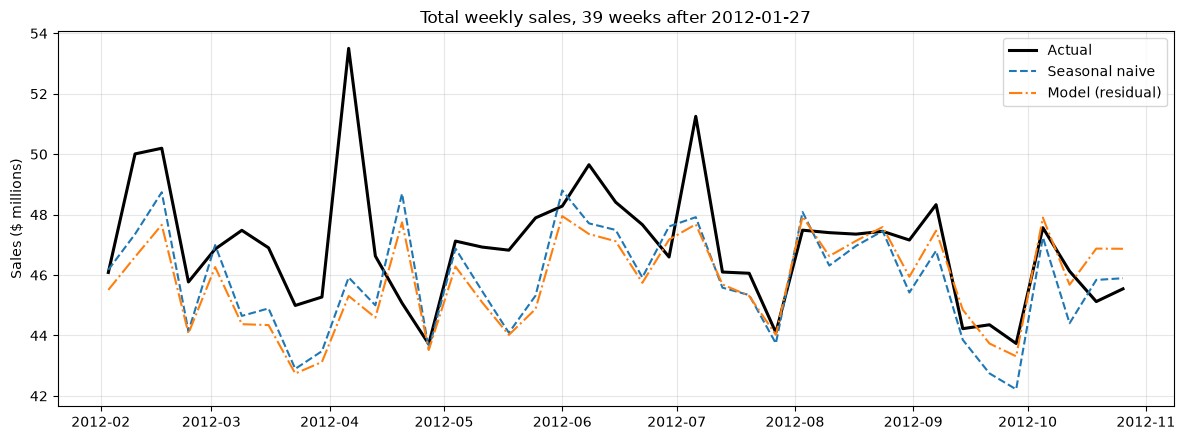

In [29]:
weekly = val_rows.groupby("Date")[["y", "base", "pred_model"]].sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(weekly.index, weekly["y"], label="Actual", linewidth=2.2, color="black")
ax.plot(weekly.index, weekly["base"], label="Seasonal naive", linestyle="--")
ax.plot(weekly.index, weekly["pred_model"], label="Model (residual)", linestyle="-.")
ax.set_title(f"Total weekly sales, 39 weeks after {TAG}")
ax.set_ylabel("Sales ($ millions)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
REPORT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(REPORT_DIR / f"forecast_vs_actual_{TAG}.png", dpi=150)
plt.show()

## 11. What to write up

Fill these in from **your** numbers, in your own words:

1. Which model has the lowest WMAE, and by how much compared with seasonal naive?
2. Is the gap larger in holiday or non-holiday weeks? In early or late horizon weeks?
3. Look at the plot: which weeks does each model get most wrong? (Check Thanksgiving, Christmas and the weeks just after.)
4. Which departments are hardest? Does it match the EDA findings (for example Dept 47 with many negative values)?
5. If the model did not beat seasonal naive, give your best explanation, with evidence from the tables above.

**Limitations to state honestly**
- One evaluation window, so the result may not hold for other periods. A stronger design repeats this at several cutoffs.
- Only one Christmas in the training data.
- `features.csv` (weather, fuel price, CPI, unemployment, markdowns) is not used yet.

**Ideas for next steps**
- Average lag weeks 51-53 more cleverly around Christmas and Easter.
- Compare with per-series ETS or STL models.
- Add markdowns once they are available for the training window.

## 12. Diagnose: why does the model lose in the first 13 weeks?

The results show the model is worse than seasonal naive in weeks 1-13 (Nov to Jan) and better in weeks 14-39. The plot shows it **overshooting the Christmas run-up**. A likely cause:

- In training, the only Christmas is 2010, and those rows have **no last-year value** (the data starts Feb 2010), so their base is a plain level and the Christmas jump lands in the residual. The model learns "close to Christmas, add a lot".
- In the evaluation window the base is last year's value, which **already contains** the Christmas peak. If the model adds its learned jump again, the peak is counted twice.

The table checks this. Compare what actually changed versus last year with what the model added.

In [30]:
d = val_rows[val_rows["base_is_lag52"] == 1].copy()
d["bucket"] = pd.cut(d["DaysToXmas"], [-15, -1, 14, 28, 59, 60],
                     labels=["Dec 26-31", "0-14 days before", "15-28 days before", "29-59 days before", "far (60+)"])
d["actual_minus_base"] = d["y"] - d["base"]
d["model_added"] = d["pred_model"] - d["base"]
diag = d.groupby("bucket", observed=True).agg(
    rows=("y", "size"),
    actual_minus_last_year=("actual_minus_base", "mean"),
    model_added=("model_added", "mean"),
).round(0)
diag

,rows,actual_minus_last_year,model_added
bucket,,,
far (60+),112437,395.0,-7.0


**How to read it:** if `model_added` is clearly positive where `actual_minus_last_year` is near zero or negative (the weeks just before Christmas), the double-counting explanation is supported. Training rows with a last-year value contain no Christmas at all, so the model cannot learn that case.

## 13. A fix to try: learn corrections only where last year's value exists

If the base is the fallback level (no last-year value), the residual means something different from when the base is last year's sales. We train only on rows where `base_is_lag52 == 1`, and use plain seasonal naive wherever the model has no such evidence.

In [31]:
mask = train_rows["base_is_lag52"] == 1
print("Training rows with a last-year value:", f"{mask.sum():,}", "of", f"{len(train_rows):,}")
print("Do any of them fall within 28 days before Christmas?",
      bool(((train_rows.loc[mask, "DaysToXmas"] >= 0) & (train_rows.loc[mask, "DaysToXmas"] <= 28)).any()))

model_b = HistGradientBoostingRegressor(
    loss="absolute_error", categorical_features=[c in CATEGORICAL for c in FEATURES],
    learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=50,
    l2_regularization=1.0, early_stopping=False, random_state=42)
model_b.fit(
    design(train_rows[mask]),
    (train_rows.loc[mask, "y"] - train_rows.loc[mask, "base"]).to_numpy(dtype=float, copy=True),
    sample_weight=train_rows.loc[mask, "weight"].to_numpy(dtype=float, copy=True))

val_rows["pred_model_lag52only"] = np.where(
    val_rows["base_is_lag52"] == 1, val_rows["base"] + model_b.predict(design(val_rows)), val_rows["base"])

preds["HistGradientBoosting (trained on rows with last-year value)"] = "pred_model_lag52only"
results = pd.DataFrame([
    {"Model": n, "WMAE": wmae(val_rows["y"], val_rows[c], val_rows["IsHoliday"]),
     "MAE": mae(val_rows["y"], val_rows[c])} for n, c in preds.items()
]).sort_values("WMAE").reset_index(drop=True)
results.to_csv(REPORT_DIR / f"results_{TAG}.csv", index=False)
results.round(2)

Training rows with a last-year value: 1,453,791 of 2,112,789
Do any of them fall within 28 days before Christmas? True


,Model,WMAE,MAE
0,HistGradientBoosting (residual),1701.06,1697.36
1,HistGradientBoosting (trained on rows with las...,1741.41,1736.32
2,Seasonal naive,1803.03,1801.47
3,Last observed,3198.66,3125.86


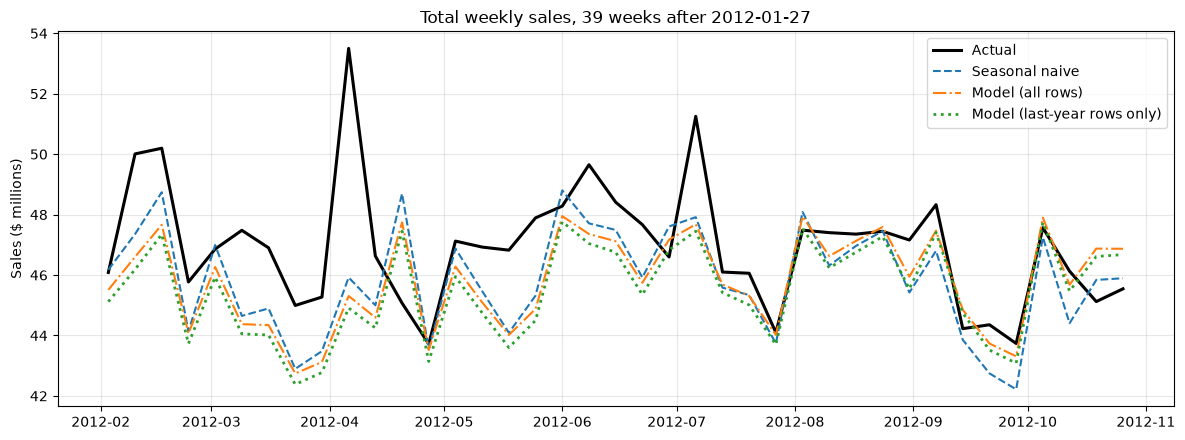

In [32]:
weekly = val_rows.groupby("Date")[["y", "base", "pred_model", "pred_model_lag52only"]].sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(weekly.index, weekly["y"], label="Actual", linewidth=2.2, color="black")
ax.plot(weekly.index, weekly["base"], label="Seasonal naive", linestyle="--")
ax.plot(weekly.index, weekly["pred_model"], label="Model (all rows)", linestyle="-.")
ax.plot(weekly.index, weekly["pred_model_lag52only"], label="Model (last-year rows only)", linestyle=":", linewidth=2)
ax.set_title(f"Total weekly sales, 39 weeks after {TAG}")
ax.set_ylabel("Sales ($ millions)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
fig.savefig(REPORT_DIR / f"forecast_vs_actual_{TAG}.png", dpi=150)   # replaces the 2-model plot from section 10
plt.show()

**Caution:** this variant was chosen after looking at the evaluation window, so a gain here is only a hint. To trust it, repeat the whole notebook with a second cutoff. `CUTOFF = "2012-01-27"` gives a different window (Feb to Oct 2012, no Christmas) and a training set with two Christmases. Report both windows in the README, whichever way the result goes.